In [5]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [17]:
df = pd.read_csv('/Users/nasy/Documents/ml_lr/ml_labs_mai/Classification/data/Titanic-Dataset.csv')

df['Title'] = df['Name'].str.extract(r',\s*([^.]*)\.')[0].str.strip()
df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')

num_features = ['Age', 'Fare', 'SibSp', 'Parch']
cat_features = ['Pclass', 'Sex', 'Embarked', 'Title']

df['Age'] = df['Age'].fillna(df['Age'].median())
df["Cabin"] = df["Cabin"].fillna("Unknown")

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title']
X = df[features]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=RANDOM_STATE
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Доля класса 1:', round(y_train.mean(), 3), round(y_test.mean(), 3))

num_features = ['Age', 'SibSp', 'Parch', 'Fare']
cat_features = ['Pclass', 'Sex', 'Embarked', 'Title']

numeric = Pipeline([
    ('missing', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
categorical = Pipeline([
    ('missing', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric, num_features),
    ('cat', categorical, cat_features)
])

Train: (712, 8) Test: (179, 8)
Доля класса 1: 0.383 0.385


## Выбираем модель - baseline (CatBoost)

In [7]:
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

In [19]:
from sklearn.model_selection import cross_validate

baseline = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.05,
    l2_leaf_reg=3,
    verbose=False,
    random_seed=RANDOM_STATE,
    thread_count=1,
    allow_writing_files=False
)

baseline_cv = cross_validate(
    baseline,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=1
)

print('Исходные параметры: iterations=300, depth=4, learning_rate=0.05, l2_leaf_reg=3')
print('Baseline CV F1:', round(baseline_cv['test_score'].mean(), 3))
print('CV std:', round(baseline_cv['test_score'].std(), 3))
print('Baseline Train F1:', round(baseline_cv['train_score'].mean(), 3))

Исходные параметры: iterations=300, depth=4, learning_rate=0.05, l2_leaf_reg=3
Baseline CV F1: 0.774
CV std: 0.042
Baseline Train F1: 0.895


### Гиперпараметры

| Параметр | Смысл | Гипотеза |
|---|---|---|
| `iterations` | Количество деревьев в ансамбле | Малое число деревьев может привести к недообучению, слишком большое — к переобучению и увеличению времени обучения |
| `depth` | Максимальная глубина деревьев | Небольшая глубина ограничивает сложность модели, большая позволяет учитывать более сложные взаимодействия признаков, но повышает риск переобучения |
| `learning_rate` | Величина вклада каждого нового дерева | Малое значение требует большего количества итераций, слишком большое может ухудшить устойчивость обучения |

Параметр `l2_leaf_reg` фиксируется равным 3 и не участвует в оптимизации.

Для **Grid Search** используем следующую сетку:

- `iterations`: 150, 300, 450, 600
- `depth`: 3, 4, 5
- `learning_rate`: 0.01, 0.03, 0.05, 0.1

Всего получаем **4 × 3 × 4 = 48 комбинаций**. При пятифолдовой кросс-валидации потребуется 240 обучений моделей.

Для **Random Search** расширяем диапазоны гиперпараметров и проводим **48 случайных испытаний**.

Оба метода используют одинаковые признаки, разбиения кросс-валидации и основную метрику F1-score. Это позволяет сравнить качество найденных конфигураций, время поиска и эффективность использования вычислительного бюджета.

При этом пространства поиска различаются: Grid Search систематически перебирает заранее заданные значения, а Random Search исследует более широкий диапазон случайным образом.

## Grid Search

In [22]:
grid_params = {
    'iterations': [150, 300, 450, 600],
    'depth': [3, 4, 5],
    'learning_rate': [0.01, 0.03, 0.05, 0.1]
}

n_grid = int(np.prod([len(v) for v in grid_params.values()]))

print('Комбинаций:', n_grid)
print('Обучений CV:', n_grid * cv.n_splits)

grid = GridSearchCV(
    baseline,
    grid_params,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

start = time.perf_counter()

grid.fit(X_train_scaled, y_train)

grid_time = time.perf_counter() - start

print('Grid: лучшее F1:', round(grid.best_score_, 3))
print('Grid: параметры:', grid.best_params_)
print('Grid: секунд:', round(grid_time, 1))

Комбинаций: 48
Обучений CV: 240
Grid: лучшее F1: 0.775
Grid: параметры: {'depth': 3, 'iterations': 450, 'learning_rate': 0.1}
Grid: секунд: 4.3


## Random Search 

In [25]:
random_params = {
    'iterations': [150, 300, 450, 600],
    'depth': [3, 4, 5],
    'learning_rate': [0.01, 0.03, 0.05, 0.1]
}

random_search = RandomizedSearchCV(
    baseline,
    random_params,
    n_iter=n_grid,
    scoring='f1',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    return_train_score=True,
    refit=True
)

start = time.perf_counter()

random_search.fit(X_train_scaled, y_train)

random_time = time.perf_counter() - start

print('Random: комбинаций:', len(random_search.cv_results_['params']))
print('Random: лучшее F1:', round(random_search.best_score_, 3))
print('Random: параметры:', random_search.best_params_)
print('Random: секунд:', round(random_time, 1))

Random: комбинаций: 48
Random: лучшее F1: 0.775
Random: параметры: {'learning_rate': 0.1, 'iterations': 450, 'depth': 3}
Random: секунд: 24.6


## Сравнение

,Method,Combinations,Fits (CV),Best CV F1,"Time, sec"
0,Grid Search,48,240,0.775,4.323
1,Random Search,48,240,0.775,24.578


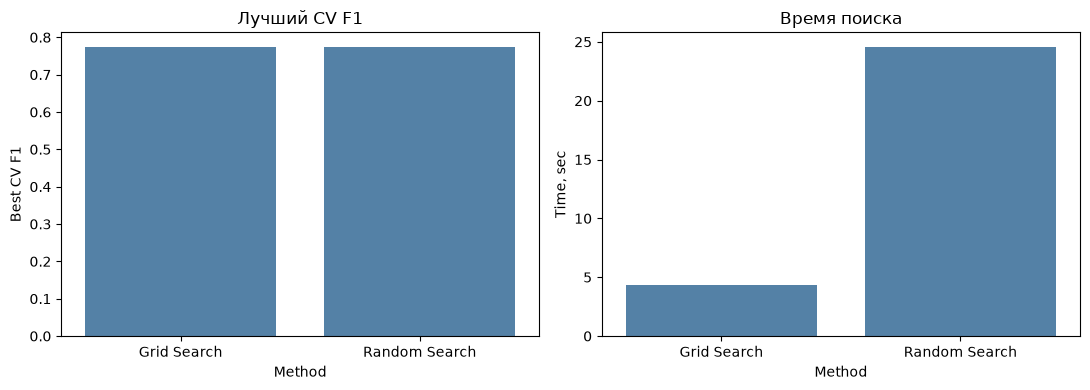

In [26]:
search_results = pd.DataFrame([
    {
        'Method': 'Grid Search',
        'Combinations': len(grid.cv_results_['params']),
        'Fits (CV)': len(grid.cv_results_['params']) * cv.n_splits,
        'Best CV F1': grid.best_score_,
        'Time, sec': grid_time
    },
    {
        'Method': 'Random Search',
        'Combinations': len(random_search.cv_results_['params']),
        'Fits (CV)': len(random_search.cv_results_['params']) * cv.n_splits,
        'Best CV F1': random_search.best_score_,
        'Time, sec': random_time
    }
])

display(search_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(
    data=search_results,
    x='Method',
    y='Best CV F1',
    ax=axes[0],
    color='steelblue'
)

sns.barplot(
    data=search_results,
    x='Method',
    y='Time, sec',
    ax=axes[1],
    color='steelblue'
)

axes[0].set_title('Лучший CV F1')
axes[1].set_title('Время поиска')

plt.tight_layout()
plt.show()

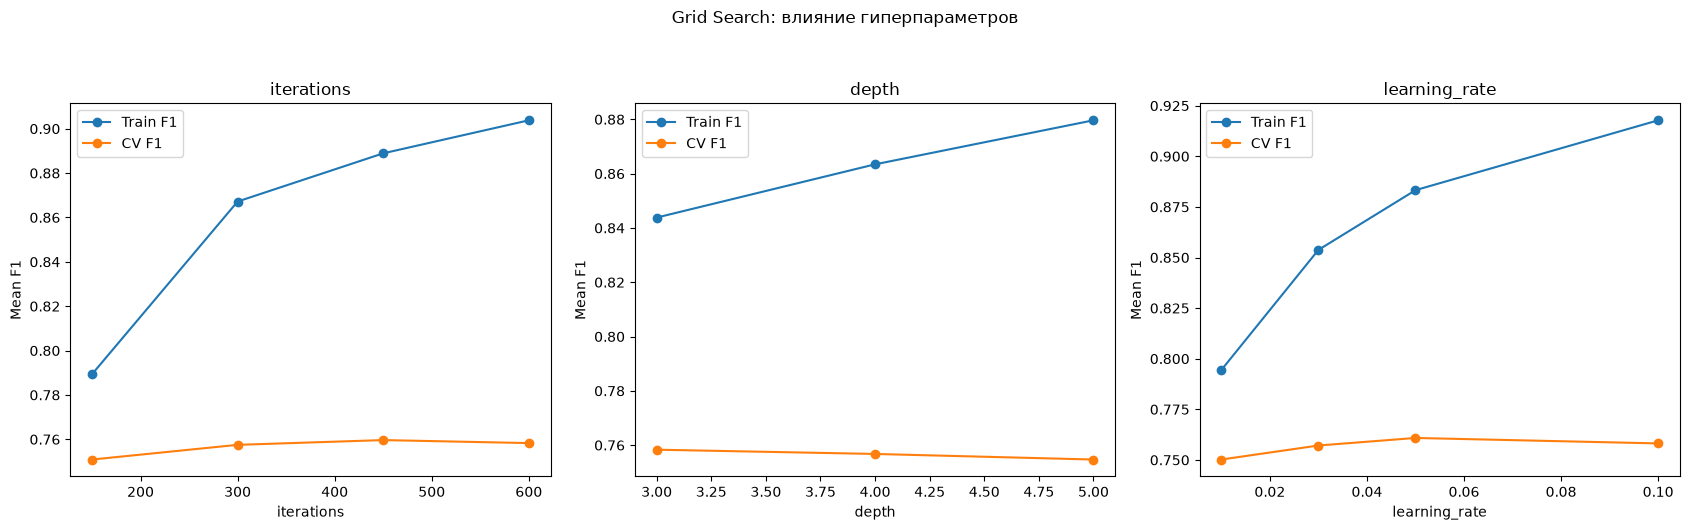

In [27]:
grid_df = pd.DataFrame(grid.cv_results_)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, name in zip(axes, ['iterations', 'depth', 'learning_rate']):

    stats = (
        grid_df.groupby('param_' + name)[
            ['mean_train_score', 'mean_test_score']
        ]
        .mean()
        .sort_index()
    )

    ax.plot(
        stats.index.astype(float),
        stats['mean_train_score'],
        marker='o',
        label='Train F1'
    )

    ax.plot(
        stats.index.astype(float),
        stats['mean_test_score'],
        marker='o',
        label='CV F1'
    )

    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel('Mean F1')
    ax.legend()

plt.suptitle('Grid Search: влияние гиперпараметров', y=1.05)
plt.tight_layout()
plt.show()

,Depth,Train F1,CV F1
0,2,0.823,0.747
1,3,0.867,0.762
2,4,0.895,0.774
3,5,0.913,0.762
4,6,0.922,0.765
5,7,0.936,0.758
6,8,0.948,0.759


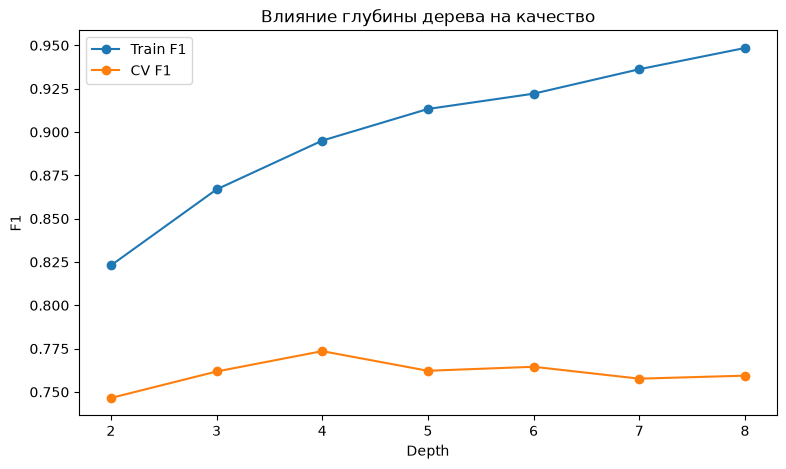

In [28]:
depth_results = []

for depth in [2, 3, 4, 5, 6, 7, 8]:

    model = clone(baseline)
    model.set_params(depth=depth)

    scores = cross_validate(
        model,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring='f1',
        return_train_score=True,
        n_jobs=1
    )

    depth_results.append({
        'Depth': depth,
        'Train F1': scores['train_score'].mean(),
        'CV F1': scores['test_score'].mean()
    })

depth_df = pd.DataFrame(depth_results)

display(depth_df.round(3))

plt.figure(figsize=(9, 5))

plt.plot(
    depth_df['Depth'],
    depth_df['Train F1'],
    marker='o',
    label='Train F1'
)

plt.plot(
    depth_df['Depth'],
    depth_df['CV F1'],
    marker='o',
    label='CV F1'
)

plt.xlabel('Depth')
plt.ylabel('F1')
plt.title('Влияние глубины дерева на качество')
plt.legend()
plt.show()

In [29]:
grid_fold_scores = [
    grid.cv_results_[f'split{i}_test_score'][grid.best_index_]
    for i in range(cv.n_splits)
]

random_fold_scores = [
    random_search.cv_results_[f'split{i}_test_score'][random_search.best_index_]
    for i in range(cv.n_splits)
]

folds = pd.DataFrame({
    'Fold': range(1, cv.n_splits + 1),
    'Baseline': baseline_cv['test_score'],
    'Grid Search': grid_fold_scores,
    'Random Search': random_fold_scores
})

display(folds.round(3))

,Fold,Baseline,Grid Search,Random Search
0,1,0.774,0.778,0.778
1,2,0.743,0.743,0.743
2,3,0.851,0.819,0.819
3,4,0.732,0.757,0.757
4,5,0.768,0.777,0.777


In [30]:
fold_summary = (
    folds.drop(columns='Fold')
    .agg(['mean', 'std', 'min', 'max'])
    .T
)

display(fold_summary.round(3))

,mean,std,min,max
Baseline,0.774,0.047,0.732,0.851
Grid Search,0.775,0.029,0.743,0.819
Random Search,0.775,0.029,0.743,0.819


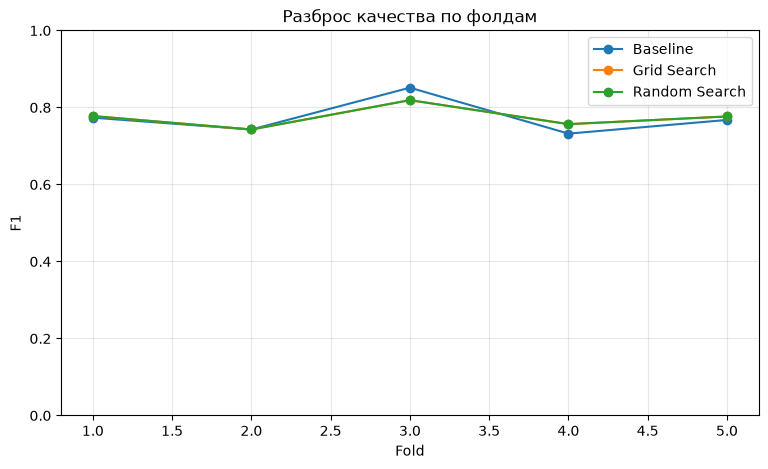

In [31]:
folds.set_index('Fold').plot(
    marker='o',
    figsize=(9, 5)
)

plt.ylabel('F1')
plt.xlabel('Fold')
plt.title('Разброс качества по фолдам')
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

In [32]:
candidates = {
    'Baseline': (baseline, baseline_cv['test_score'].mean()),
    'Grid Search': (grid.best_estimator_, grid.best_score_),
    'Random Search': (random_search.best_estimator_, random_search.best_score_)
}

final_rows = []

for name, (model, cv_f1) in candidates.items():

    fitted_model = clone(model)
    fitted_model.fit(X_train_scaled, y_train)

    pred = fitted_model.predict(X_test_scaled)

    final_rows.append({
        'Model': name,
        'CV F1': cv_f1,
        'Test F1': f1_score(y_test, pred),
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred)
    })

final_results = pd.DataFrame(final_rows)

display(final_results.round(3))

,Model,CV F1,Test F1,Accuracy,Precision,Recall
0,Baseline,0.774,0.773,0.832,0.810,0.739
1,Grid Search,0.775,0.746,0.821,0.825,0.681
2,Random Search,0.775,0.746,0.821,0.825,0.681


In [36]:
selected = (
    'Grid Search'
    if grid.best_score_ >= random_search.best_score_
    else 'Random Search'
)

print('Лучшая стратегия по CV:', selected)

cv_improvement = (
    max(grid.best_score_, random_search.best_score_)
    - baseline_cv['test_score'].mean()
)

test_improvement = (
    final_results.set_index('Model').loc[selected, 'Test F1']
    - final_results.set_index('Model').loc['Baseline', 'Test F1']
)

print('Прирост CV F1:', round(cv_improvement, 3))

Лучшая стратегия по CV: Grid Search
Прирост CV F1: 0.001


В проведённом эксперименте Grid Search показал более высокое значение F1-score на кросс-валидации по сравнению с Random Search. Это может объясняться тем, что Grid Search систематически исследовал все комбинации заранее выбранной сетки, тогда как Random Search случайным образом выбирал ограниченное количество комбинаций из более широкого пространства. В результате случайный поиск мог пропустить более удачные сочетания гиперпараметров.

Однако полученный результат не означает, что Grid Search всегда превосходит Random Search. При большом пространстве гиперпараметров Random Search может оказаться эффективнее, поскольку позволяет исследовать больше различных значений при ограниченном вычислительном бюджете.